# Assignment 2: Convolutional Networks on Cats vs. Dogs
**From-scratch convnet vs. pretrained VGG16, and the effect of training sample size**

*Python (TensorFlow/Keras) notebook run on Kaggle (2× Tesla T4). All outputs below are from the actual run.*

## Task and how this notebook answers it
| Assignment step | What was done | Section |
|---|---|---|
| **Q1** Train from scratch on 1,000 train / 500 val / 500 test images, reduce overfitting | Convnet trained from scratch, n = 1,000 | Part A, Q1 |
| **Q2** Increase the training size and re-optimize | Same pipeline, n = 5,000 | Part A, Q2 |
| **Q3** Find the best training sample size (from scratch) | Sweep n = 500, 1,000, 2,000, 5,000, 10,000, 20,000 | Part A, Q3 |
| **Q4** Repeat Q1-Q3 with a pretrained network | VGG16 (ImageNet): feature extraction, then fine-tuning, n = 500 to 10,000 | Part B |
| **Report** Summary table / graph and the sample-size vs. network relationship | Summary table, graphs, conclusions | Part C |

## Design in one paragraph
* **Fixed evaluation sets.** One balanced validation set (250 cats + 250 dogs) and one balanced test set (250 + 250), drawn once with seed 123 and *never* used for training. Every model, at every n, is evaluated on the same 500 + 500 images, so results are directly comparable.
* **Nested, balanced training subsets** (n/2 cats + n/2 dogs) drawn from the remaining 24,000 labeled images.
* **Overfitting controls** (both networks): data augmentation (horizontal flip, rotation, zoom), dropout 0.5, early stopping on validation loss with restoration of the best weights, and learning-rate reduction on plateau.
* **Model choice by validation accuracy** (as the rubric specifies); **test accuracy** is the number not used for any decision and is the honest estimate.
* Image size 180×180, batch size 32, labels cat = 0 / dog = 1, seed 123.


## 0. Setup
Imports, library versions and GPU check.

In [1]:
import os, shutil, random, time, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))   # should list one GPU

SEED = 123
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow: 2.20.0
Keras: 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Data
### 1.1 Locate and unzip the training images
The Kaggle *Dogs vs. Cats* competition provides 25,000 labeled images (12,500 per class). The files are unzipped to the working directory and labeled from the file name (`cat.*.jpg` / `dog.*.jpg`).

In [2]:
# Chunk 2: locate and unzip the Dogs vs. Cats training images
import glob
zip_path = glob.glob('/kaggle/input/**/train.zip', recursive=True)[0]
print('Using', zip_path)
RAW = '/kaggle/working/raw'
if not os.path.exists(RAW):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(RAW)
files = sorted(glob.glob(RAW + '/**/*.jpg', recursive=True))
labels = ['cat' if os.path.basename(f).startswith('cat') else 'dog' for f in files]
df = pd.DataFrame({'path': files, 'label': labels})
print(df.label.value_counts())

Using /kaggle/input/competitions/dogs-vs-cats/train.zip
label
cat    12500
dog    12500
Name: count, dtype: int64


### 1.2 Fixed validation / test sets and a training pool
The images of each class are shuffled once (seed 123). The first 250 of each class become the validation set, the next 250 the test set; the remaining 12,000 per class form the pool from which training subsets are drawn. `make_train_dir(n)` creates a balanced training folder of n images (symbolic links, so no data is copied).

In [3]:
# Chunk 3: fixed validation/test sets (250 cats + 250 dogs each) and a training pool
cats = df[df.label == 'cat'].sample(frac=1, random_state=SEED).reset_index(drop=True)
dogs = df[df.label == 'dog'].sample(frac=1, random_state=SEED).reset_index(drop=True)
val_df = pd.concat([cats[:250], dogs[:250]])
test_df = pd.concat([cats[250:500], dogs[250:500]])
pool_cats = cats[500:].reset_index(drop=True)
pool_dogs = dogs[500:].reset_index(drop=True)
BASE = '/kaggle/working/data'

def link_files(paths, label, dest):
    out = os.path.join(dest, label)
    os.makedirs(out, exist_ok=True)
    for p in paths:
        link = os.path.join(out, os.path.basename(p))
        if not os.path.exists(link):
            os.symlink(p, link)

for lab in ['cat', 'dog']:
    link_files(val_df[val_df.label == lab].path, lab, BASE + '/validation')
    link_files(test_df[test_df.label == lab].path, lab, BASE + '/test')

def make_train_dir(n):
    # balanced training subset (n/2 cats + n/2 dogs); subsets are nested
    dest = BASE + '/train_' + str(n)
    link_files(pool_cats.path[:n // 2], 'cat', dest)
    link_files(pool_dogs.path[:n // 2], 'dog', dest)
    return dest

print(len(os.listdir(BASE + '/validation/cat')), len(os.listdir(BASE + '/validation/dog')), len(os.listdir(BASE + '/test/cat')), len(os.listdir(BASE + '/test/dog')))

250 250 250 250


### 1.3 Helpers: loaders, augmentation, callbacks and result logging
`log_result` evaluates a trained model on the validation and test sets and appends one row to the results table (also written to `results.csv`).

In [4]:
# Chunk 4: data loaders, augmentation, callbacks and result tracking
IMG = (180, 180)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_ds(path, shuffle=True):
    ds = keras.utils.image_dataset_from_directory(path, image_size=IMG, batch_size=BATCH, label_mode='binary', shuffle=shuffle, seed=SEED)
    return ds.prefetch(AUTOTUNE)

val_ds = load_ds(BASE + '/validation', shuffle=False)
test_ds = load_ds(BASE + '/test', shuffle=False)

def make_augmentation():
    return keras.Sequential([layers.RandomFlip('horizontal'), layers.RandomRotation(0.1), layers.RandomZoom(0.2)])

def make_callbacks(patience=8):
    return [keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)]

results = []
histories = {}

def log_result(approach, question, n, history, model, mins):
    val_acc = model.evaluate(val_ds, verbose=0)[1]
    test_acc = model.evaluate(test_ds, verbose=0)[1]
    results.append(dict(approach=approach, question=question, n_train=n, epochs_run=len(history.history['loss']), val_acc=round(val_acc, 4), test_acc=round(test_acc, 4), minutes=round(mins, 1)))
    pd.DataFrame(results).to_csv('/kaggle/working/results.csv', index=False)
    print(approach, '| n =', n, '| val acc =', round(val_acc, 3), '| test acc =', round(test_acc, 3), '|', round(mins, 1), 'min')

def plot_run(history, title):
    h = history.history
    plt.figure(figsize=(6, 3.5))
    plt.plot(h['accuracy'], label='train')
    plt.plot(h['val_accuracy'], label='validation')
    plt.title(title)
    plt.xlabel('epoch')
    plt.ylabel('accuracy')
    plt.legend()
    plt.show()

Found 500 files belonging to 2 classes.
Found 500 files belonging to 2 classes.


I0000 00:00:1792890213.980372      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792890213.986435      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## Part A: Convnet trained from scratch (Q1-Q3)
### A.1 Architecture
Input → augmentation → rescaling → five convolution blocks (32, 64, 128, 256 filters with max-pooling, then a final 256-filter convolution) → flatten → dropout 0.5 → one sigmoid unit. About **991 K parameters**, Adam (lr 1e-3), early stopping (patience 10) and learning-rate reduction on plateau. The same architecture is used at every training size, so differences between sizes are due to the data, not to model changes.

In [5]:
# Chunk 5: from-scratch convnet and run function
def build_scratch():
    inputs = keras.Input(shape=IMG + (3,))
    x = make_augmentation()(inputs)
    x = layers.Rescaling(1. / 255)(x)
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, 3, activation='relu')(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(256, 3, activation='relu')(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = keras.Model(inputs, outputs)
    model.compile(loss='binary_crossentropy', optimizer=keras.optimizers.Adam(1e-3), metrics=['accuracy'])
    return model

def run_scratch(n, question, epochs=60):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    train_ds = load_ds(make_train_dir(n))
    model = build_scratch()
    t0 = time.time()
    history = model.fit(train_ds, epochs=epochs, validation_data=val_ds, callbacks=make_callbacks(10), verbose=2)
    log_result('Scratch', question, n, history, model, (time.time() - t0) / 60)
    histories['scratch_' + str(n)] = history
    return model

build_scratch().summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        12,545 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 991,041 (3.78 MB)

 Trainable params: 991,041 (3.78 MB)

 Non-trainable params: 0 (0.00 B)

### A.2 Q1: from scratch, 1,000 training images
The learning curves show the typical small-data pattern: training accuracy keeps improving while validation accuracy stalls and fluctuates; augmentation and dropout delay but do not remove this.

Found 1000 files belonging to 2 classes.
Epoch 1/60
32/32 - 9s - 296ms/step - accuracy: 0.4900 - loss: 0.6988 - val_accuracy: 0.5060 - val_loss: 0.6926 - learning_rate: 0.0010
Epoch 2/60
32/32 - 2s - 47ms/step - accuracy: 0.4920 - loss: 0.6933 - val_accuracy: 0.5280 - val_loss: 0.6913 - learning_rate: 0.0010
Epoch 3/60
32/32 - 2s - 47ms/step - accuracy: 0.4940 - loss: 0.6928 - val_accuracy: 0.5100 - val_loss: 0.6843 - learning_rate: 0.0010
Epoch 4/60
32/32 - 2s - 47ms/step - accuracy: 0.5160 - loss: 0.6917 - val_accuracy: 0.5320 - val_loss: 0.6866 - learning_rate: 0.0010
Epoch 5/60
32/32 - 1s - 47ms/step - accuracy: 0.5270 - loss: 0.6922 - val_accuracy: 0.5640 - val_loss: 0.6735 - learning_rate: 0.0010
Epoch 6/60
32/32 - 2s - 47ms/step - accuracy: 0.5590 - loss: 0.6840 - val_accuracy: 0.5360 - val_loss: 0.6786 - learning_rate: 0.0010
Epoch 7/60
32/32 - 2s - 47ms/step - accuracy: 0.5690 - loss: 0.6731 - val_accuracy: 0.5520 - val_loss: 0.6668 - learning_rate: 0.0010
Epoch 8/60
32/32 - 2

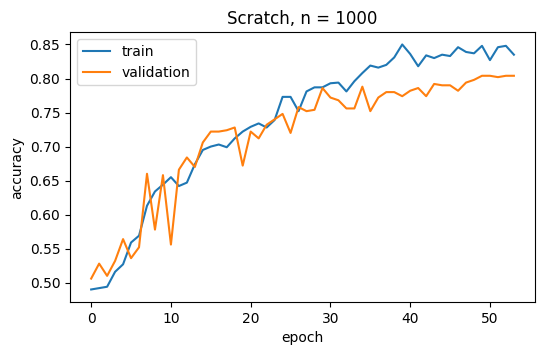

In [6]:
# Q1: from scratch, 1,000 training images
m_s1000 = run_scratch(1000, 'Q1')
plot_run(histories['scratch_1000'], 'Scratch, n = 1000')

### A.3 Q2: increase the training size and re-optimize (5,000 images)
More data, with the epoch budget re-set (50 epochs, early stopping still active). The gap between the training and validation curves narrows.

Found 5000 files belonging to 2 classes.
Epoch 1/50
157/157 - 9s - 57ms/step - accuracy: 0.5136 - loss: 0.6941 - val_accuracy: 0.5240 - val_loss: 0.6912 - learning_rate: 0.0010
Epoch 2/50
157/157 - 6s - 40ms/step - accuracy: 0.5446 - loss: 0.6833 - val_accuracy: 0.5220 - val_loss: 0.6858 - learning_rate: 0.0010
Epoch 3/50
157/157 - 6s - 40ms/step - accuracy: 0.5564 - loss: 0.6801 - val_accuracy: 0.6220 - val_loss: 0.6652 - learning_rate: 0.0010
Epoch 4/50
157/157 - 6s - 41ms/step - accuracy: 0.5932 - loss: 0.6746 - val_accuracy: 0.6540 - val_loss: 0.6380 - learning_rate: 0.0010
Epoch 5/50
157/157 - 6s - 40ms/step - accuracy: 0.6300 - loss: 0.6520 - val_accuracy: 0.6800 - val_loss: 0.6200 - learning_rate: 0.0010
Epoch 6/50
157/157 - 6s - 40ms/step - accuracy: 0.6360 - loss: 0.6407 - val_accuracy: 0.6440 - val_loss: 0.6239 - learning_rate: 0.0010
Epoch 7/50
157/157 - 6s - 40ms/step - accuracy: 0.6696 - loss: 0.6161 - val_accuracy: 0.6800 - val_loss: 0.6123 - learning_rate: 0.0010
Epoch 8

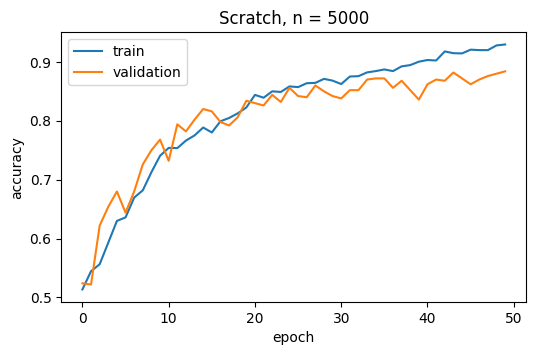

  approach question  n_train  epochs_run  val_acc  test_acc  minutes
0  Scratch       Q1     1000          54    0.792     0.734      1.5
1  Scratch       Q2     5000          50    0.880     0.886      5.2


In [7]:
# Q2: from scratch, 5,000 training images
m_s5000 = run_scratch(5000, 'Q2', epochs=50)
plot_run(histories['scratch_5000'], 'Scratch, n = 5000')
print(pd.DataFrame(results))

### A.4 Q3: sweep to find the best from-scratch sample size
The remaining sizes are run with the same settings; the epoch cap is lowered for the larger sets (40 at 10,000 and 30 at 20,000) to keep run time reasonable. Note that the runs at 5,000, 10,000 and 20,000 images ended at the epoch cap, not by early stopping, so they may be slightly under-trained.

In [8]:
# Q3: sweep of other training sample sizes (from scratch)
for n, ep in [(500, 60), (2000, 60), (10000, 40), (20000, 30)]:
    run_scratch(n, 'Q3 sweep', epochs=ep)
print(pd.DataFrame(results).sort_values('val_acc', ascending=False).to_string())

Found 500 files belonging to 2 classes.
Epoch 1/60
16/16 - 4s - 231ms/step - accuracy: 0.4920 - loss: 0.7067 - val_accuracy: 0.5000 - val_loss: 0.6929 - learning_rate: 0.0010
Epoch 2/60
16/16 - 1s - 60ms/step - accuracy: 0.5060 - loss: 0.6937 - val_accuracy: 0.5020 - val_loss: 0.6921 - learning_rate: 0.0010
Epoch 3/60
16/16 - 1s - 60ms/step - accuracy: 0.4920 - loss: 0.6946 - val_accuracy: 0.5000 - val_loss: 0.6932 - learning_rate: 0.0010
Epoch 4/60
16/16 - 1s - 59ms/step - accuracy: 0.4920 - loss: 0.6931 - val_accuracy: 0.5000 - val_loss: 0.6931 - learning_rate: 0.0010
Epoch 5/60
16/16 - 1s - 60ms/step - accuracy: 0.4780 - loss: 0.6934 - val_accuracy: 0.5000 - val_loss: 0.6931 - learning_rate: 0.0010
Epoch 6/60
16/16 - 1s - 59ms/step - accuracy: 0.4620 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.6931 - learning_rate: 5.0000e-04
Epoch 7/60
16/16 - 1s - 58ms/step - accuracy: 0.5280 - loss: 0.6930 - val_accuracy: 0.5020 - val_loss: 0.6930 - learning_rate: 5.0000e-04
Epoch 8/60
16

## Part B: Pretrained VGG16 (Q4)
VGG16 (ImageNet weights, no classifier head) with the same augmentation, followed by Flatten → Dense(256, ReLU) → Dropout 0.5 → sigmoid. Two stages:
1. **Feature extraction**: convolutional base frozen, only the new head trained (RMSprop, lr 1e-4).
2. **Fine-tuning**: only the last convolutional block (`block5`) unfrozen and trained with a much smaller learning rate (RMSprop, lr 1e-5).

In [9]:
# Chunk 6: pretrained VGG16 (feature extraction, then fine-tuning block5)
def build_pretrained():
    conv_base = keras.applications.VGG16(weights='imagenet', include_top=False, input_shape=IMG + (3,))
    conv_base.trainable = False
    inputs = keras.Input(shape=IMG + (3,))
    x = make_augmentation()(inputs)
    x = layers.Lambda(keras.applications.vgg16.preprocess_input)(x)
    x = conv_base(x)
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = keras.Model(inputs, outputs)
    model.compile(loss='binary_crossentropy', optimizer=keras.optimizers.RMSprop(1e-4), metrics=['accuracy'])
    return model, conv_base

def run_pretrained(n, question, fe_epochs=15, ft_epochs=10):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    train_ds = load_ds(make_train_dir(n))
    model, conv_base = build_pretrained()
    # Stage 1: feature extraction with the frozen VGG16 base
    t0 = time.time()
    h1 = model.fit(train_ds, epochs=fe_epochs, validation_data=val_ds, callbacks=make_callbacks(4), verbose=2)
    log_result('Pretrained: feature extraction', question, n, h1, model, (time.time() - t0) / 60)
    histories['pre_fe_' + str(n)] = h1
    # Stage 2: fine-tune block5 with a very small learning rate
    conv_base.trainable = True
    for layer in conv_base.layers:
        layer.trainable = layer.name.startswith('block5')
    model.compile(loss='binary_crossentropy', optimizer=keras.optimizers.RMSprop(1e-5), metrics=['accuracy'])
    t1 = time.time()
    h2 = model.fit(train_ds, epochs=ft_epochs, validation_data=val_ds, callbacks=make_callbacks(4), verbose=2)
    log_result('Pretrained: fine-tuned', question, n, h2, model, (time.time() - t1) / 60)
    histories['pre_ft_' + str(n)] = h2
    return model

### B.1 Q4 (Q1 setting): 1,000 training images

Found 1000 files belonging to 2 classes.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
32/32 - 12s - 371ms/step - accuracy: 0.8210 - loss: 2.7017 - val_accuracy: 0.9560 - val_loss: 0.2768 - learning_rate: 1.0000e-04
Epoch 2/15
32/32 - 5s - 143ms/step - accuracy: 0.9050 - loss: 1.0943 - val_accuracy: 0.9660 - val_loss: 0.2400 - learning_rate: 1.0000e-04
Epoch 3/15
32/32 - 5s - 141ms/step - accuracy: 0.9380 - loss: 0.6236 - val_accuracy: 0.9700 - val_loss: 0.2773 - learning_rate: 1.0000e-04
Epoch 4/15
32/32 - 5s - 142ms/step - accuracy: 0.9400 - loss: 0.5375 - val_accuracy: 0.9660 - val_loss: 0.3489 - learning_rate: 1.0000e-04
Epoch 5/15
32/32 - 5s - 144ms/step - accuracy: 0.9490 - loss: 0.3643 - val_accuracy: 0.9820 - val_loss: 0.1709 - learning_rate: 1.0000e-04
Epoch 6/15
32/32 - 5s - 144ms/step - accuracy: 0.9610 - loss: 0.2973 - val_accuracy: 0.9840 - val_loss: 0.1252 - learning_rate: 1.0000e-04
Epoch 7/15
32/32 - 5s - 144ms/step - accuracy: 0.9640 - loss: 0.2785 - va

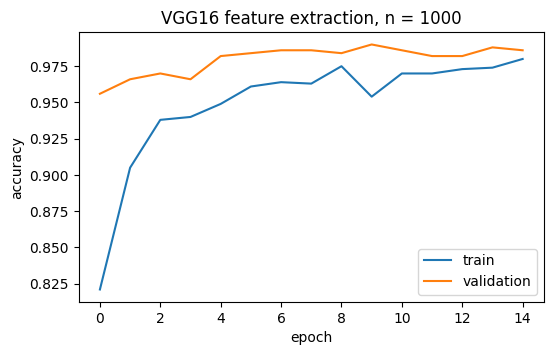

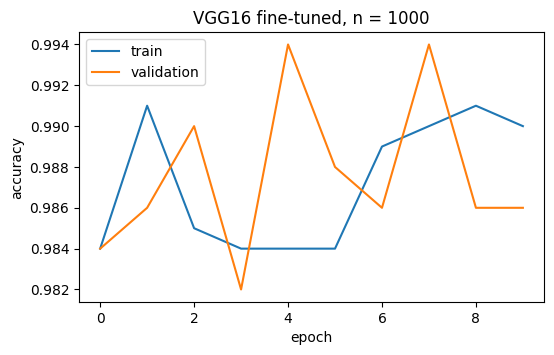

In [10]:
# Q4 (Q1 setting): pretrained VGG16, 1,000 training images
m_p1000 = run_pretrained(1000, 'Q1')
plot_run(histories['pre_fe_1000'], 'VGG16 feature extraction, n = 1000')
plot_run(histories['pre_ft_1000'], 'VGG16 fine-tuned, n = 1000')

### B.2 Q4 (Q2 setting): 5,000 training images

Found 5000 files belonging to 2 classes.
Epoch 1/15
157/157 - 18s - 117ms/step - accuracy: 0.8938 - loss: 1.2003 - val_accuracy: 0.9820 - val_loss: 0.0961 - learning_rate: 1.0000e-04
Epoch 2/15
157/157 - 16s - 104ms/step - accuracy: 0.9424 - loss: 0.4839 - val_accuracy: 0.9820 - val_loss: 0.0935 - learning_rate: 1.0000e-04
Epoch 3/15
157/157 - 16s - 105ms/step - accuracy: 0.9504 - loss: 0.3280 - val_accuracy: 0.9860 - val_loss: 0.0760 - learning_rate: 1.0000e-04
Epoch 4/15
157/157 - 16s - 105ms/step - accuracy: 0.9556 - loss: 0.2552 - val_accuracy: 0.9880 - val_loss: 0.0475 - learning_rate: 1.0000e-04
Epoch 5/15
157/157 - 16s - 104ms/step - accuracy: 0.9682 - loss: 0.1666 - val_accuracy: 0.9900 - val_loss: 0.0656 - learning_rate: 1.0000e-04
Epoch 6/15
157/157 - 16s - 105ms/step - accuracy: 0.9678 - loss: 0.1923 - val_accuracy: 0.9880 - val_loss: 0.0467 - learning_rate: 1.0000e-04
Epoch 7/15
157/157 - 16s - 104ms/step - accuracy: 0.9678 - loss: 0.1632 - val_accuracy: 0.9920 - val_loss: 

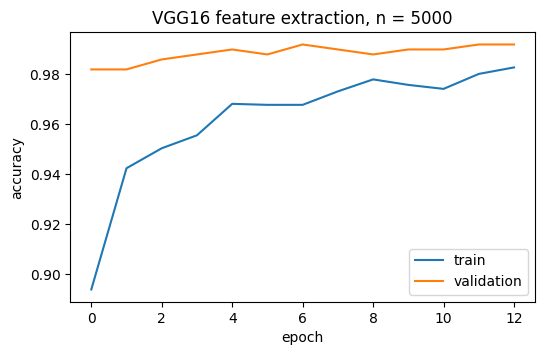

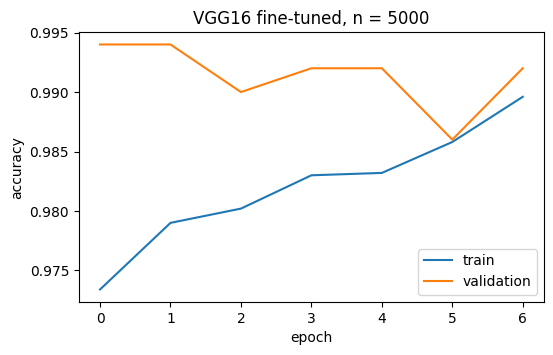

In [11]:
# Q4 (Q2 setting): pretrained VGG16, 5,000 training images
m_p5000 = run_pretrained(5000, 'Q2')
plot_run(histories['pre_fe_5000'], 'VGG16 feature extraction, n = 5000')
plot_run(histories['pre_ft_5000'], 'VGG16 fine-tuned, n = 5000')

### B.3 Q4 (Q3 setting): sweep over other sample sizes
Sample sizes may differ from Part A (allowed by the assignment): n = 500, 2,000 and 10,000, with slightly smaller epoch caps (12 for feature extraction, 8 for fine-tuning) because the pretrained models converge within a handful of epochs. n = 20,000 was not run for the pretrained network because accuracy was already flat by 10,000.

In [12]:
# Q4 (Q3 setting): pretrained VGG16 sweep over other training sizes
for n in [500, 2000, 10000]:
    run_pretrained(n, 'Q3 sweep', fe_epochs=12, ft_epochs=8)
print(pd.DataFrame(results).to_string())

Found 500 files belonging to 2 classes.
Epoch 1/12
16/16 - 5s - 326ms/step - accuracy: 0.7480 - loss: 4.9036 - val_accuracy: 0.9560 - val_loss: 0.4338 - learning_rate: 1.0000e-04
Epoch 2/12
16/16 - 3s - 193ms/step - accuracy: 0.8980 - loss: 1.2023 - val_accuracy: 0.9640 - val_loss: 0.2286 - learning_rate: 1.0000e-04
Epoch 3/12
16/16 - 3s - 193ms/step - accuracy: 0.9340 - loss: 0.6156 - val_accuracy: 0.9660 - val_loss: 0.2059 - learning_rate: 1.0000e-04
Epoch 4/12
16/16 - 3s - 192ms/step - accuracy: 0.9340 - loss: 0.6204 - val_accuracy: 0.9620 - val_loss: 0.3669 - learning_rate: 1.0000e-04
Epoch 5/12
16/16 - 3s - 193ms/step - accuracy: 0.9280 - loss: 0.6645 - val_accuracy: 0.9760 - val_loss: 0.1654 - learning_rate: 1.0000e-04
Epoch 6/12
16/16 - 3s - 191ms/step - accuracy: 0.9640 - loss: 0.4334 - val_accuracy: 0.9760 - val_loss: 0.1678 - learning_rate: 1.0000e-04
Epoch 7/12
16/16 - 3s - 192ms/step - accuracy: 0.9620 - loss: 0.2517 - val_accuracy: 0.9700 - val_loss: 0.3118 - learning_rate

## Part C: Results summary
The next cell builds the full results table, lists the best configuration per approach (selected by validation accuracy) and draws test accuracy against training size.

                      approach question  n_train  epochs_run  val_acc  test_acc  minutes
Pretrained: feature extraction Q3 sweep      500           9    0.976     0.960      0.5
Pretrained: feature extraction       Q1     1000          15    0.986     0.960      1.3
Pretrained: feature extraction Q3 sweep     2000          11    0.990     0.964      1.4
Pretrained: feature extraction       Q2     5000          13    0.988     0.968      3.6
Pretrained: feature extraction Q3 sweep    10000          12    0.992     0.974      6.3
        Pretrained: fine-tuned Q3 sweep      500           8    0.984     0.968      0.5
        Pretrained: fine-tuned       Q1     1000          10    0.994     0.966      0.9
        Pretrained: fine-tuned Q3 sweep     2000           8    0.992     0.974      1.2
        Pretrained: fine-tuned       Q2     5000           7    0.990     0.964      2.3
        Pretrained: fine-tuned Q3 sweep    10000           7    0.992     0.976      4.3
                     

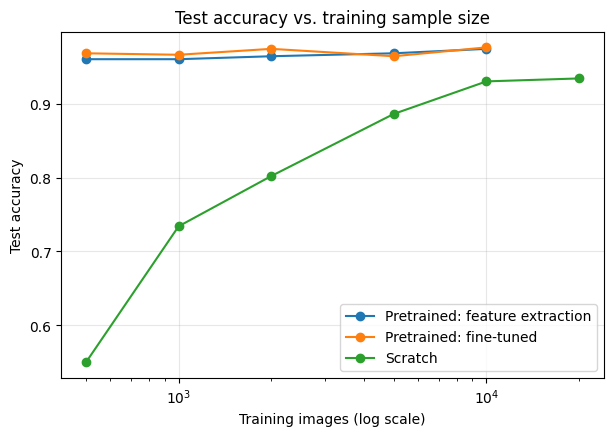

In [13]:
# Chunk 7: summary table and graph
res = pd.DataFrame(results)
print(res.sort_values(['approach', 'n_train']).to_string(index=False))
best = res.loc[res.groupby('approach').val_acc.idxmax()]
print(best.to_string(index=False))
plt.figure(figsize=(7, 4.5))
for name, g in res.groupby('approach'):
    g = g.sort_values('n_train')
    plt.plot(g.n_train, g.test_acc, marker='o', label=name)
plt.xscale('log')
plt.xlabel('Training images (log scale)')
plt.ylabel('Test accuracy')
plt.title('Test accuracy vs. training sample size')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('/kaggle/working/accuracy_vs_sample_size.png', dpi=150, bbox_inches='tight')
plt.show()
res.to_csv('/kaggle/working/results.csv', index=False)

### C.1 Final results (copied from the run above; also saved as `results.csv`)
| Approach | Question | n (train) | Epochs run | Val acc | Test acc | Minutes |
|---|---|---:|---:|---:|---:|---:|
| Scratch | Q3 sweep | 500 | 30 | 56.0% | 55.0% | 0.5 |
| Scratch | Q1 | 1,000 | 54 | 79.2% | 73.4% | 1.5 |
| Scratch | Q3 sweep | 2,000 | 59 | 81.4% | 80.2% | 2.7 |
| Scratch | Q2 | 5,000 | 50 | 88.0% | 88.6% | 5.2 |
| Scratch | Q3 sweep | 10,000 | 40 | 93.0% | 93.0% | 8.1 |
| Scratch | Q3 sweep | 20,000 | 30 | 95.2% | 93.4% | 11.8 |
| Pretrained: feature extraction | Q3 sweep | 500 | 9 | 97.6% | 96.0% | 0.5 |
| Pretrained: feature extraction | Q1 | 1,000 | 15 | 98.6% | 96.0% | 1.3 |
| Pretrained: feature extraction | Q3 sweep | 2,000 | 11 | 99.0% | 96.4% | 1.4 |
| Pretrained: feature extraction | Q2 | 5,000 | 13 | 98.8% | 96.8% | 3.6 |
| Pretrained: feature extraction | Q3 sweep | 10,000 | 12 | 99.2% | 97.4% | 6.3 |
| Pretrained: fine-tuned | Q3 sweep | 500 | 8 | 98.4% | 96.8% | 0.5 |
| Pretrained: fine-tuned | Q1 | 1,000 | 10 | 99.4% | 96.6% | 0.9 |
| Pretrained: fine-tuned | Q3 sweep | 2,000 | 8 | 99.2% | 97.4% | 1.2 |
| Pretrained: fine-tuned | Q2 | 5,000 | 7 | 99.0% | 96.4% | 2.3 |
| Pretrained: fine-tuned | Q3 sweep | 10,000 | 7 | 99.2% | 97.6% | 4.3 |

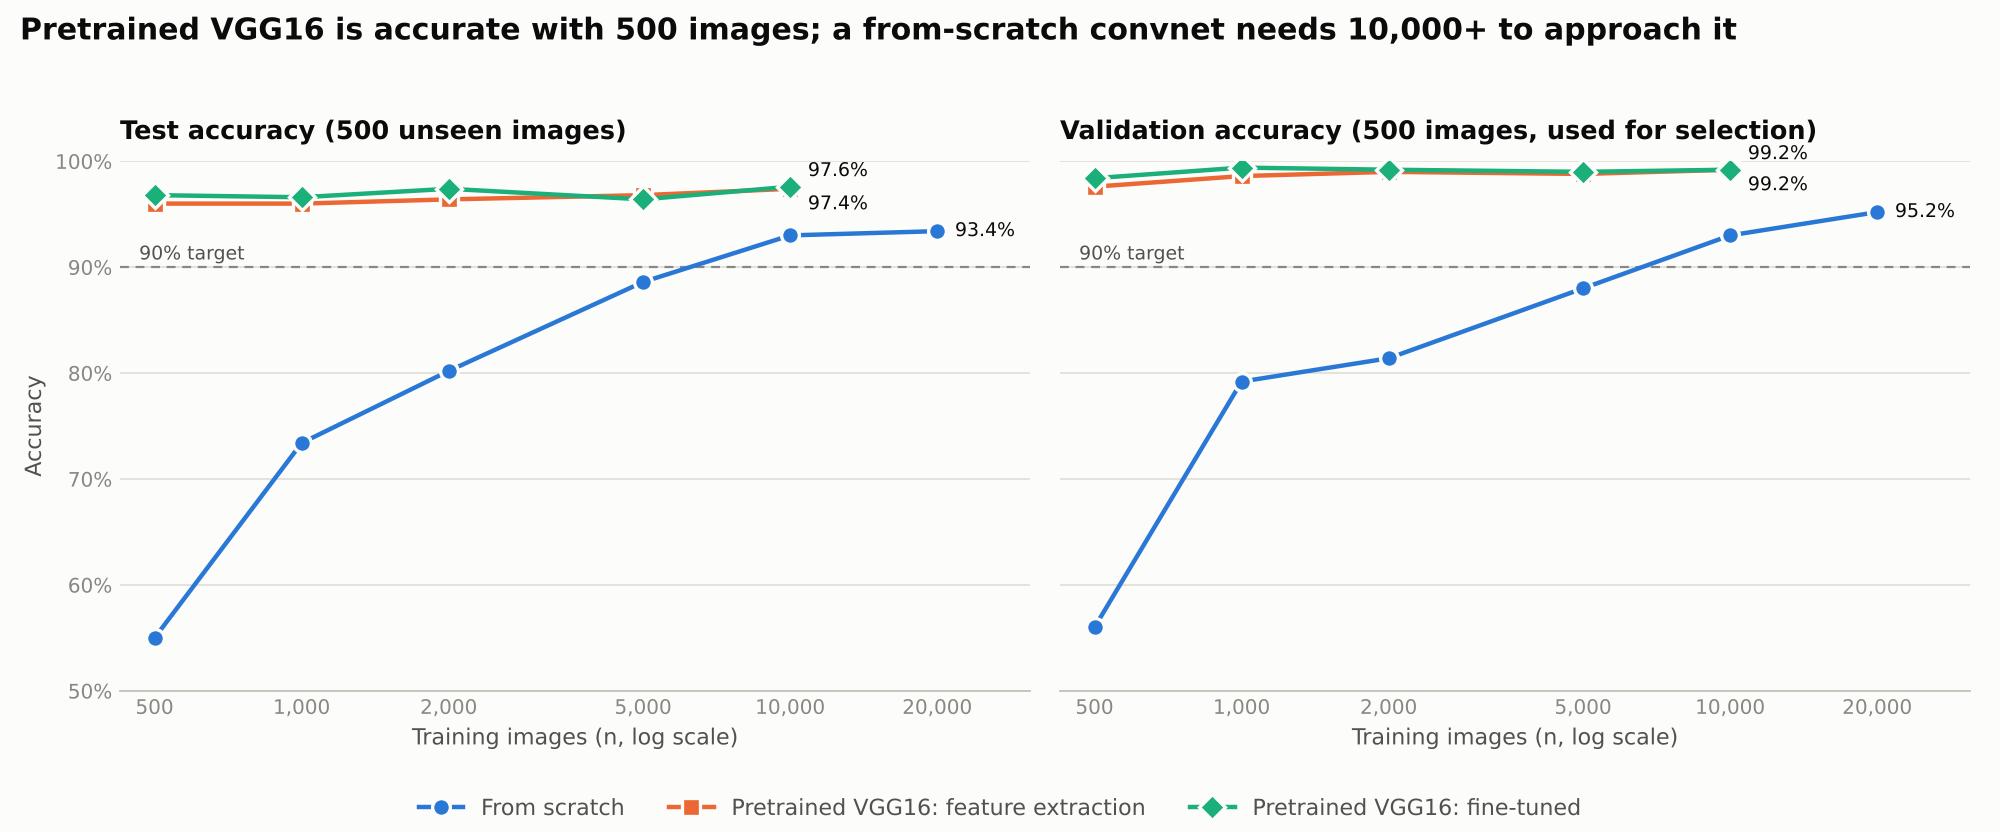

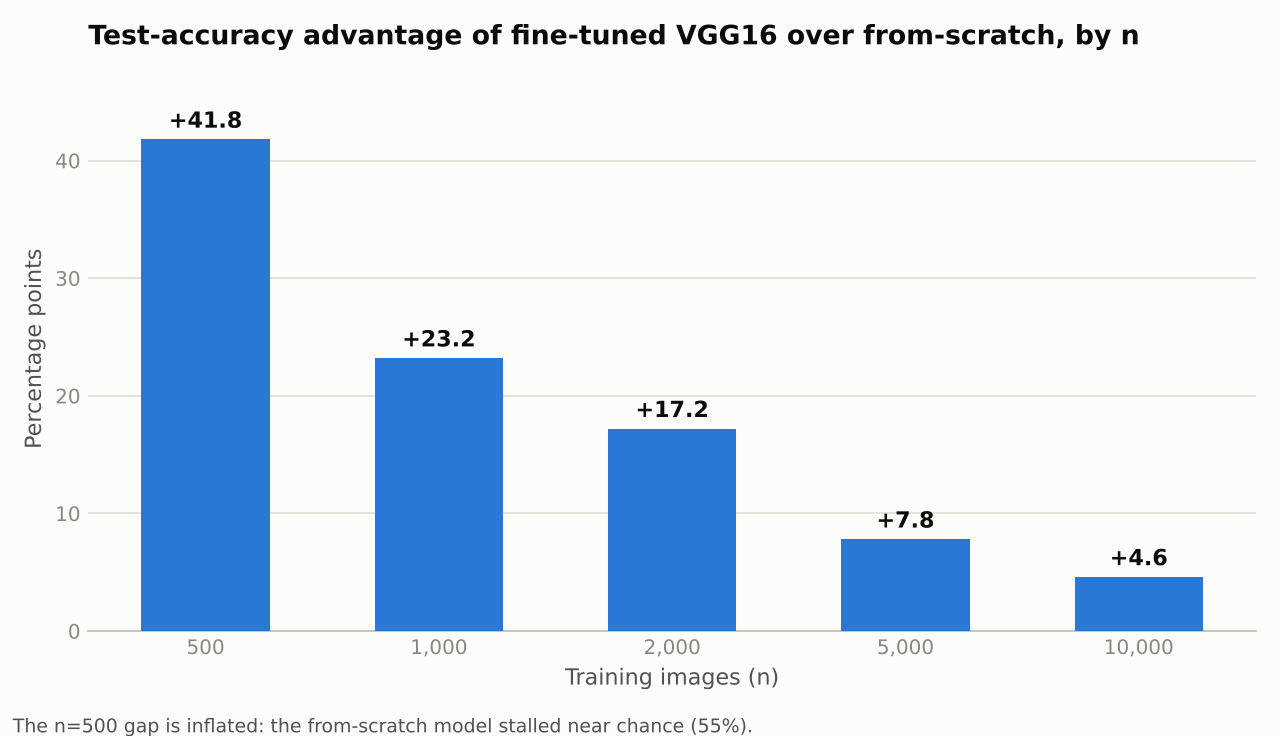

### C.2 Pretrained advantage over from-scratch (test accuracy, fine-tuned VGG16 minus scratch, same n)
| n | Scratch | Fine-tuned VGG16 | Gap (pts) |
|---:|---:|---:|---:|
| 500 | 55.0% | 96.8% | +41.8 |
| 1,000 | 73.4% | 96.6% | +23.2 |
| 2,000 | 80.2% | 97.4% | +17.2 |
| 5,000 | 88.6% | 96.4% | +7.8 |
| 10,000 | 93.0% | 97.6% | +4.6 |

The n = 500 gap is inflated: the scratch model at 500 images stalled near chance (55%).

## Conclusions
**Q1 (scratch, n = 1,000).** 79.2% validation / 73.4% test. With 1,000 images a from-scratch convnet overfits heavily even with augmentation, dropout and early stopping.

**Q2 (scratch, n = 5,000).** 88.0% validation / 88.6% test, about 9 points better on validation than Q1 (+15 points on test).

**Q3 (best from-scratch size).** Accuracy rises steadily with n: test 55.0% (500), 73.4% (1,000), 80.2% (2,000), 88.6% (5,000), 93.0% (10,000), 93.4% (20,000). The best validation accuracy is at **n = 20,000 (95.2% val / 93.4% test)**, but returns diminish: going from 10,000 to 20,000 images doubles the data (and raises training time from 8.1 to 11.8 min even with a lower epoch cap) for only +0.4 points on test. **10,000 to 20,000 images are needed to exceed 90%** from scratch; with 5,000 or fewer the from-scratch model stays below 90% validation.

**Q4 (pretrained VGG16).** Accuracy is high and almost flat in n: test 96.0% to 97.6% for every size from 500 to 10,000, validation 97.6% to 99.4%. Fine-tuning `block5` gives a small, inconsistent gain over feature extraction (differences of 1 point or less are within noise on a 500-image test set). Best by validation: **fine-tuned, n = 1,000 (99.4% val / 96.6% test)**; best test: fine-tuned, n = 10,000 (97.6%). **Q3 for the pretrained network:** feature extraction at n = 10,000 (99.2% val / 97.4% test) beats its own Q1 (98.6% / 96.0%) and Q2 (98.8% / 96.8%) settings on both metrics, and fine-tuned n = 10,000 beats its Q1 and Q2 on test (97.6% vs 96.6% and 96.4%); the validation gain is not universal (fine-tuned Q1 is 99.4% vs 99.2%), and all these differences are within noise. Since accuracy is flat, ~1,000 images is the cost-effective choice (about 2.2 minutes for both stages).

### What is the relationship between training sample size and choice of network?
* **Small samples favour the pretrained network by a wide margin.** At n = 1,000 fine-tuned VGG16 beats the scratch model by 23.2 points on test; at n = 2,000 by 17.2.
* **The advantage shrinks as data grows** (7.8 points at 5,000; 4.6 points at 10,000) because the scratch model keeps improving while the pretrained one has already saturated.
* **Pretrained features substitute for data.** VGG16 with only 500 training images scores higher (96.8% test, 98.4% validation) than the scratch network with 20,000 images (93.4% test, 95.2% validation). The test difference of 3.4 points is modest relative to the noise of a 500-image test set, so read it as "at least as good with 40 times fewer images".
* **Practical rule:** with fewer than a few thousand labeled images use a pretrained network; a from-scratch network only becomes competitive once there are about 10,000 or more images, and even then it stays a few points behind.

### Rubric check: validation accuracy
Scratch Q1 (79.2%) and Q2 (88.0%) are below the 90% mark; from scratch, 90%+ is reached at n ≥ 10,000 (93.0% and 95.2%). All pretrained runs are at 97.6% or higher.

### Limitations
* Each configuration was run once (single seed), so small differences are not statistically reliable. With 500 test images one image is 0.2 points and the standard error is roughly 0.8 to 2 points depending on accuracy; pretrained differences of about 1 point or less should not be interpreted.
* The validation set was used for early stopping, for choosing the best run and for the rubric figure, so validation accuracy is slightly optimistic; test accuracy is the unbiased estimate.
* The scratch run at n = 500 (56% val) stalled near chance; it was stopped by early stopping and not tuned further. The scratch runs at 5,000, 10,000 and 20,000 ended at the epoch cap while still improving slightly.
* The same scratch architecture and hyperparameters were used for all sizes (not re-tuned per size); the pretrained sweep used smaller epoch caps (12 / 8) than Q1 and Q2 (15 / 10).
* n = 24,000 (all remaining data) was not tested, and the pretrained network was not run at n = 20,000.
